<a href="https://colab.research.google.com/github/ichakraborty260001031/TechSoC-26/blob/main/AI%20ML/cifar100_hyperparameter_tuning_my_work.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-100 Image Classification: Hyperparameter Tuning Challenge

Welcome! In this notebook you will train a small convolutional neural network (CNN) to recognise **100 kinds of objects** in tiny 32x32 colour images.

**Your mission is not just to run the code. It is to improve it.**

The model code is given to you. Your job is to change the **hyperparameters** (learning rate, batch size, dropout, and so on), run experiment after experiment, and keep a record of what worked and what did not, until you reach the best validation accuracy you can.

### How this notebook works
1. Run Steps 0 to 4 once, top to bottom (this gives you a baseline).
2. In Step 5, change **one hyperparameter at a time** and run again.
3. Every run is **logged automatically** into a results table (Step 6).
4. When you are happy with your best model, evaluate it **once** on the test set (Step 7).

> Tip: use **Runtime > Run all** the first time, then work cell by cell.

## Step 0: Set up (GPU)

Training on a CPU is very slow. Please switch to a free GPU:

**Runtime > Change runtime type > T4 GPU > Save**

Then run the cell below. You should see at least one GPU listed.

In [1]:
import random, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# A fixed seed makes your results (mostly) repeatable, so comparisons between runs are fair.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPUs found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Load a SMALL version of CIFAR-100

The full CIFAR-100 (60,000 images, about 160 MB) can be slow or fail to download on Colab. So this notebook loads a **small slice** instead:

- It **streams** only the images it needs from the Hugging Face copy of CIFAR-100 (same data as on Kaggle), so the download is a fraction of the full size.
- It keeps only **NUM_CLASSES** of the 100 classes (20 by default), which also makes training much faster.
- If streaming fails, it automatically falls back to the normal Keras download and then slices it.

You can change the three size settings below. Bigger means more accurate but slower.

We split the data into three parts:

| Part | Used for |
|------|----------|
| Train | Teaching the model |
| Validation | **Comparing your experiments** (look at it as often as you like) |
| Test | The final exam. Use it **once**, at the very end. |

If you tune using the test set, your final score will be unfairly optimistic. That is called *data leakage*, so please resist the temptation.

In [2]:
# ---------- Size settings for the short version (you may change these) ----------
NUM_CLASSES = 20      # how many of the 100 classes to keep (100 = all classes)
TRAIN_POOL = 20000    # images read from the original training set (max 50000)
TEST_POOL = 4000      # images read from the original test set (max 10000)
VAL_FRACTION = 0.15   # share of the kept training images used for validation
# Rough guide: images kept = TRAIN_POOL * NUM_CLASSES / 100 (so 20000 and 20 classes gives about 4000)

ALL_CLASS_NAMES = ['apple','aquarium_fish','baby','bear','beaver','bed','bee','beetle','bicycle','bottle',
 'bowl','boy','bridge','bus','butterfly','camel','can','castle','caterpillar','cattle',
 'chair','chimpanzee','clock','cloud','cockroach','couch','crab','crocodile','cup','dinosaur',
 'dolphin','elephant','flatfish','forest','fox','girl','hamster','house','kangaroo','keyboard',
 'lamp','lawn_mower','leopard','lion','lizard','lobster','man','maple_tree','motorcycle','mountain',
 'mouse','mushroom','oak_tree','orange','orchid','otter','palm_tree','pear','pickup_truck','pine_tree',
 'plain','plate','poppy','porcupine','possum','rabbit','raccoon','ray','road','rocket',
 'rose','sea','seal','shark','shrew','skunk','skyscraper','snail','snake','spider',
 'squirrel','streetcar','sunflower','sweet_pepper','table','tank','telephone','television','tiger','tractor',
 'train','trout','tulip','turtle','wardrobe','whale','willow_tree','wolf','woman','worm']
assert len(ALL_CLASS_NAMES) == 100


def load_stream(split, n):
    # Reads only n images from the Hugging Face copy of CIFAR-100 (small download)
    from datasets import load_dataset
    ds = load_dataset("uoft-cs/cifar100", split=split, streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10000)
    xs, ys = [], []
    for ex in ds.take(n):
        xs.append(np.array(ex["img"].convert("RGB"), dtype=np.uint8))
        ys.append(ex["fine_label"])
    return np.stack(xs), np.array(ys)


try:
    x_tr, y_tr = load_stream("train", TRAIN_POOL)
    x_te, y_te = load_stream("test", TEST_POOL)
    print("Loaded a small slice via Hugging Face streaming.")
except Exception as e:
    print("Streaming did not work (", repr(e)[:120], ").")
    print("Falling back to the Keras download (about 160 MB, one time only).")
    (xa, ya), (xb, yb) = keras.datasets.cifar100.load_data(label_mode="fine")
    r = np.random.RandomState(SEED)
    ia, ib = r.permutation(len(xa))[:TRAIN_POOL], r.permutation(len(xb))[:TEST_POOL]
    x_tr, y_tr, x_te, y_te = xa[ia], ya.flatten()[ia], xb[ib], yb.flatten()[ib]

# Keep only some classes, and renumber them 0 .. NUM_CLASSES-1
chosen = np.sort(np.random.RandomState(SEED).choice(100, NUM_CLASSES, replace=False))
remap = {int(c): i for i, c in enumerate(chosen)}
CLASS_NAMES = [ALL_CLASS_NAMES[c] for c in chosen]

def keep_classes(x, y):
    m = np.isin(y, chosen)
    return x[m], np.array([remap[int(c)] for c in y[m]])

x_tr, y_tr = keep_classes(x_tr, y_tr)
x_test, y_test = keep_classes(x_te, y_te)

# Train / validation split
perm = np.random.RandomState(SEED).permutation(len(x_tr))
n_val = int(len(x_tr) * VAL_FRACTION)
x_val, y_val = x_tr[perm[:n_val]], y_tr[perm[:n_val]]
x_train, y_train = x_tr[perm[n_val:]], y_tr[perm[n_val:]]

print(f"Classes: {NUM_CLASSES} | Train: {len(x_train)} | Validation: {len(x_val)} | Test: {len(x_test)}")
print("Classes kept:", CLASS_NAMES)
print("Random guessing would score about", f"{100 / NUM_CLASSES:.1f}%")

README.md:   0%|          | 0.00/9.98k [00:00<?, ?B/s]

Loaded a small slice via Hugging Face streaming.
Classes: 20 | Train: 3391 | Validation: 598 | Test: 812
Classes kept: ['apple', 'beaver', 'bowl', 'bridge', 'caterpillar', 'clock', 'dolphin', 'elephant', 'forest', 'keyboard', 'lizard', 'lobster', 'orange', 'rose', 'shark', 'skyscraper', 'snail', 'squirrel', 'sweet_pepper', 'train']
Random guessing would score about 5.0%


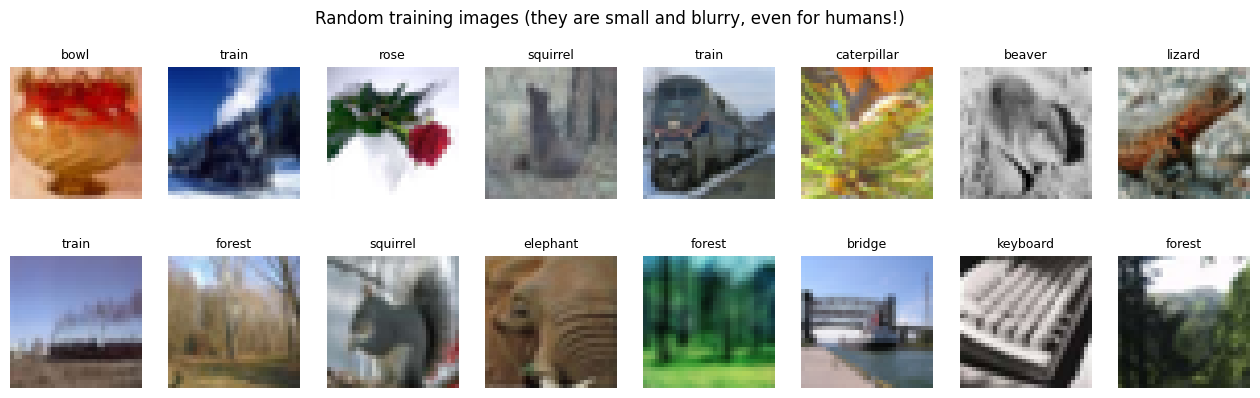

In [3]:
# Take a look at some images
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, np.random.RandomState(0).choice(len(x_train), 16, replace=False)):
    ax.imshow(x_train[i])
    ax.set_title(CLASS_NAMES[y_train[i]], fontsize=9)
    ax.axis("off")
plt.suptitle("Random training images (they are small and blurry, even for humans!)")
plt.show()

## Step 2: The model (you do not need to edit this)

This function builds a CNN from a dictionary of settings called `cfg`. Each block has two convolution layers, batch normalisation, max pooling and dropout. The number of filters doubles after every block.

Read it, get curious about it, but all the tuning in this challenge happens through the `cfg` dictionary.

In [4]:
def build_model(cfg):
    reg = keras.regularizers.l2(cfg["l2"]) if cfg["l2"] > 0 else None

    inputs = keras.Input(shape=(32, 32, 3))
    x = layers.Rescaling(1.0 / 255)(inputs)          # turn pixel values 0-255 into 0-1

    # Data augmentation: random changes to training images (only active while training)
    if cfg["augment"]:
        x = layers.RandomFlip("horizontal")(x)
        x = layers.RandomTranslation(0.1, 0.1)(x)
        x = layers.RandomRotation(0.05)(x)

    filters = cfg["base_filters"]
    for _ in range(cfg["num_blocks"]):
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(cfg["dropout"])(x)
        filters *= 2

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(cfg["dense_units"], activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(cfg["dropout"])(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs)


def get_optimizer(cfg):
    name, lr = cfg["optimizer"].lower(), cfg["learning_rate"]
    if name == "adam":
        return keras.optimizers.Adam(learning_rate=lr)
    if name == "adamw":
        return keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4)
    if name == "sgd":
        return keras.optimizers.SGD(learning_rate=lr, momentum=0.9, nesterov=True)
    if name == "rmsprop":
        return keras.optimizers.RMSprop(learning_rate=lr)
    raise ValueError("optimizer must be one of: adam, adamw, sgd, rmsprop")

## Step 3: The experiment runner (you do not need to edit this)

`run_experiment(cfg, notes)` does everything for one experiment:
- builds and trains the model with your settings,
- stops early if the model stops improving (saves time),
- plots the learning curves,
- **adds a row to your results table** and saves it to `experiment_log.csv`,
- keeps a copy of the best model so far in `best_model.keras`.

The `notes` text is for you: write what you changed and why.

In [5]:
LOG_FILE, BEST_MODEL_FILE = "experiment_log.csv", "best_model.keras"

# Reload earlier results if the file exists (handy if you rerun this cell)
if os.path.exists(LOG_FILE):
    experiment_log = pd.read_csv(LOG_FILE).to_dict("records")
else:
    experiment_log = []
best_val_so_far = max([r["val_acc"] for r in experiment_log], default=0.0) if os.path.exists(BEST_MODEL_FILE) else 0.0


def make_ds(x, y, batch_size, training):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    if training:
        ds = ds.shuffle(len(x), seed=SEED)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def plot_history(history, title):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
    a1.plot(history.history["loss"], label="train"); a1.plot(history.history["val_loss"], label="validation")
    a1.set_title("Loss (lower is better)"); a1.set_xlabel("epoch"); a1.legend()
    a2.plot(history.history["accuracy"], label="train"); a2.plot(history.history["val_accuracy"], label="validation")
    a2.set_title("Accuracy (higher is better)"); a2.set_xlabel("epoch"); a2.legend()
    fig.suptitle(title); plt.show()


def run_experiment(cfg, notes=""):
    global best_val_so_far
    keras.backend.clear_session()
    tf.random.set_seed(SEED)

    train_ds = make_ds(x_train, y_train, cfg["batch_size"], training=True)
    val_ds = make_ds(x_val, y_val, cfg["batch_size"], training=False)

    model = build_model(cfg)
    model.compile(optimizer=get_optimizer(cfg), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

    callbacks = [keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=cfg["patience"],
                                               restore_best_weights=True)]
    if cfg["use_lr_schedule"]:
        callbacks.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6))

    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs"], callbacks=callbacks, verbose=2)
    minutes = (time.time() - start) / 60

    h = history.history
    best = int(np.argmax(h["val_accuracy"]))          # the epoch with the best validation accuracy
    row = {"run": len(experiment_log) + 1, "notes": notes}
    row.update(cfg)
    row.update({
        "train_acc": round(h["accuracy"][best], 4),
        "val_acc": round(h["val_accuracy"][best], 4),
        "val_loss": round(h["val_loss"][best], 4),
        "gap": round(h["accuracy"][best] - h["val_accuracy"][best], 4),   # big gap = overfitting
        "best_epoch": best + 1,
        "epochs_run": len(h["loss"]),
        "minutes": round(minutes, 1),
        "params": model.count_params(),
    })
    experiment_log.append(row)
    pd.DataFrame(experiment_log).to_csv(LOG_FILE, index=False)

    if row["val_acc"] > best_val_so_far:
        best_val_so_far = row["val_acc"]
        model.save(BEST_MODEL_FILE)
        print("New best model saved!")

    plot_history(history, f"Run {row['run']}: {notes}")
    print(f"Run {row['run']} | val_acc = {row['val_acc']:.4f} | train_acc = {row['train_acc']:.4f} | "
          f"gap = {row['gap']:.4f} | {row['minutes']} min")
    return model

## Step 4: Baseline run

This is the starting point. It uses reasonable but un-tuned settings. Run it and note the validation accuracy. **This is the number you are trying to beat.**

Here is what each setting means:

| Setting | Meaning |
|---------|---------|
| `learning_rate` | How big a step the model takes when learning. Too high: unstable. Too low: very slow. |
| `batch_size` | How many images are used for each update. |
| `epochs` | Maximum passes over the training data (early stopping may end sooner). |
| `optimizer` | The learning algorithm: `adam`, `adamw`, `sgd`, `rmsprop`. |
| `dropout` | Fraction of neurons randomly switched off while training (fights overfitting). |
| `l2` | Weight penalty (fights overfitting). `0` means off. |
| `base_filters` | Width of the first conv layer. It doubles each block. Bigger = more capacity. |
| `num_blocks` | Depth of the network (1 to 4). |
| `dense_units` | Size of the fully connected layer before the output. |
| `augment` | `True` randomly flips, shifts and rotates training images. |
| `use_lr_schedule` | `True` halves the learning rate when progress stalls. |
| `patience` | Epochs to wait without improvement before stopping early. |

Epoch 1/30
53/53 - 33s - 614ms/step - accuracy: 0.1940 - loss: 2.5650 - val_accuracy: 0.0736 - val_loss: 2.9812
Epoch 2/30
53/53 - 1s - 14ms/step - accuracy: 0.2678 - loss: 2.2396 - val_accuracy: 0.0819 - val_loss: 3.3419
Epoch 3/30
53/53 - 1s - 12ms/step - accuracy: 0.3155 - loss: 2.1174 - val_accuracy: 0.1037 - val_loss: 3.8722
Epoch 4/30
53/53 - 1s - 11ms/step - accuracy: 0.3618 - loss: 1.9806 - val_accuracy: 0.1187 - val_loss: 3.5955
Epoch 5/30
53/53 - 0s - 9ms/step - accuracy: 0.3834 - loss: 1.9286 - val_accuracy: 0.0920 - val_loss: 3.5867
Epoch 6/30
53/53 - 0s - 9ms/step - accuracy: 0.4288 - loss: 1.7901 - val_accuracy: 0.1271 - val_loss: 4.3033
Epoch 7/30
53/53 - 0s - 9ms/step - accuracy: 0.4353 - loss: 1.7397 - val_accuracy: 0.1488 - val_loss: 3.6045
Epoch 8/30
53/53 - 0s - 9ms/step - accuracy: 0.4639 - loss: 1.6538 - val_accuracy: 0.1722 - val_loss: 3.1980
Epoch 9/30
53/53 - 0s - 9ms/step - accuracy: 0.4777 - loss: 1.6048 - val_accuracy: 0.2007 - val_loss: 3.1096
Epoch 10/30
5

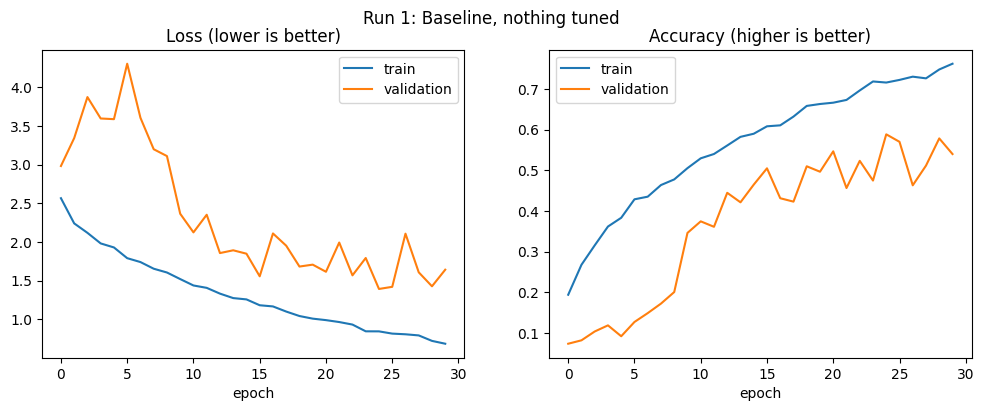

Run 1 | val_acc = 0.5886 | train_acc = 0.7160 | gap = 0.1274 | 0.8 min


In [6]:
baseline_cfg = {
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 30,
    "optimizer": "adam",
    "dropout": 0.25,
    "l2": 0.0,
    "base_filters": 32,
    "num_blocks": 3,
    "dense_units": 256,
    "augment": False,
    "use_lr_schedule": False,
    "patience": 6,
}

model = run_experiment(baseline_cfg, notes="Baseline, nothing tuned")

## Step 5: YOUR TURN, run experiments

### The golden rule: change ONE thing at a time
If you change three settings and the score goes up, you will not know which change helped.

### The loop
1. Look at the learning curves and the `gap` column from your last run.
2. Form a guess ("The model is overfitting, so more dropout might help").
3. Copy your best config, change **one** value, and write a clear `notes` message.
4. Run it. Check the table in Step 6. Repeat.

### Reading the curves
| What you see | What it probably means | Things to try |
|--------------|------------------------|---------------|
| Train and validation accuracy both low | Underfitting | Bigger model (`base_filters`, `num_blocks`), higher learning rate, train longer |
| Train accuracy high, validation much lower (large `gap`) | Overfitting | `augment=True`, more `dropout`, `l2` > 0, smaller model |
| Validation loss jumps around wildly | Learning rate too high | Lower `learning_rate`, `use_lr_schedule=True` |
| Training is very slow to improve | Learning rate too low | Raise `learning_rate` |
| Stops early at a poor score | `patience` too small | Increase `patience` and `epochs` |

### Ideas for a good search order
1. `augment` (usually a big win on CIFAR-100)
2. `learning_rate` (try 0.01, 0.003, 0.0003)
3. `dropout` (0.1, 0.3, 0.4, 0.5)
4. `use_lr_schedule` and a larger `epochs`
5. Model size: `base_filters` (64) and `num_blocks`
6. `batch_size` (32, 128) and `optimizer`
7. Finally, combine the good ideas and fine-tune around them

Below is a template. Edit the lines marked with `# CHANGE`.

Epoch 1/30
53/53 - 10s - 181ms/step - accuracy: 0.1822 - loss: 2.5597 - val_accuracy: 0.0602 - val_loss: 3.0705
Epoch 2/30
53/53 - 1s - 18ms/step - accuracy: 0.2586 - loss: 2.2724 - val_accuracy: 0.0468 - val_loss: 3.4776
Epoch 3/30
53/53 - 1s - 18ms/step - accuracy: 0.2858 - loss: 2.1899 - val_accuracy: 0.0502 - val_loss: 3.5304
Epoch 4/30
53/53 - 1s - 18ms/step - accuracy: 0.3017 - loss: 2.1235 - val_accuracy: 0.0602 - val_loss: 3.6752
Epoch 5/30
53/53 - 1s - 25ms/step - accuracy: 0.3152 - loss: 2.0894 - val_accuracy: 0.1120 - val_loss: 3.1884
Epoch 6/30
53/53 - 1s - 18ms/step - accuracy: 0.3495 - loss: 2.0017 - val_accuracy: 0.1087 - val_loss: 3.6313
Epoch 7/30
53/53 - 1s - 18ms/step - accuracy: 0.3601 - loss: 1.9742 - val_accuracy: 0.2090 - val_loss: 2.7355
Epoch 8/30
53/53 - 1s - 18ms/step - accuracy: 0.3769 - loss: 1.8843 - val_accuracy: 0.2375 - val_loss: 2.5456
Epoch 9/30
53/53 - 1s - 18ms/step - accuracy: 0.4011 - loss: 1.8251 - val_accuracy: 0.2408 - val_loss: 2.6729
Epoch 10

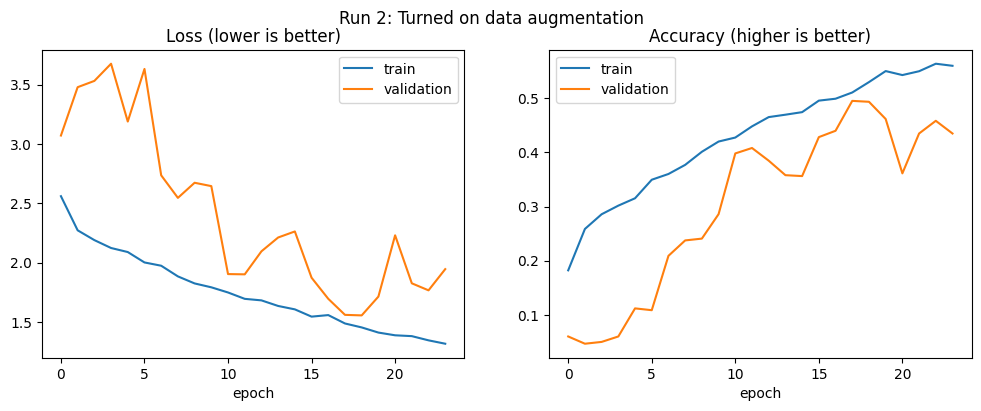

Run 2 | val_acc = 0.4950 | train_acc = 0.5105 | gap = 0.0155 | 0.5 min


In [7]:
# Experiment 2: copy of the baseline with ONE change
cfg = dict(baseline_cfg)
cfg["augment"] = True

model = run_experiment(cfg, notes="Turned on data augmentation")

Epoch 1/30
53/53 - 5s - 95ms/step - accuracy: 0.1781 - loss: 2.6002 - val_accuracy: 0.1355 - val_loss: 2.9229
Epoch 2/30
53/53 - 1s - 19ms/step - accuracy: 0.2209 - loss: 2.3473 - val_accuracy: 0.1906 - val_loss: 2.6575
Epoch 3/30
53/53 - 1s - 18ms/step - accuracy: 0.2418 - loss: 2.2931 - val_accuracy: 0.1388 - val_loss: 3.0322
Epoch 4/30
53/53 - 1s - 18ms/step - accuracy: 0.2684 - loss: 2.2259 - val_accuracy: 0.1572 - val_loss: 2.7798
Epoch 5/30
53/53 - 1s - 18ms/step - accuracy: 0.2678 - loss: 2.1999 - val_accuracy: 0.1672 - val_loss: 2.7248
Epoch 6/30
53/53 - 1s - 19ms/step - accuracy: 0.2902 - loss: 2.1675 - val_accuracy: 0.2441 - val_loss: 2.3138
Epoch 7/30
53/53 - 1s - 19ms/step - accuracy: 0.2928 - loss: 2.1358 - val_accuracy: 0.2809 - val_loss: 2.2009
Epoch 8/30
53/53 - 1s - 19ms/step - accuracy: 0.3049 - loss: 2.0831 - val_accuracy: 0.2876 - val_loss: 2.2650
Epoch 9/30
53/53 - 1s - 18ms/step - accuracy: 0.3055 - loss: 2.0845 - val_accuracy: 0.2425 - val_loss: 2.4663
Epoch 10/3

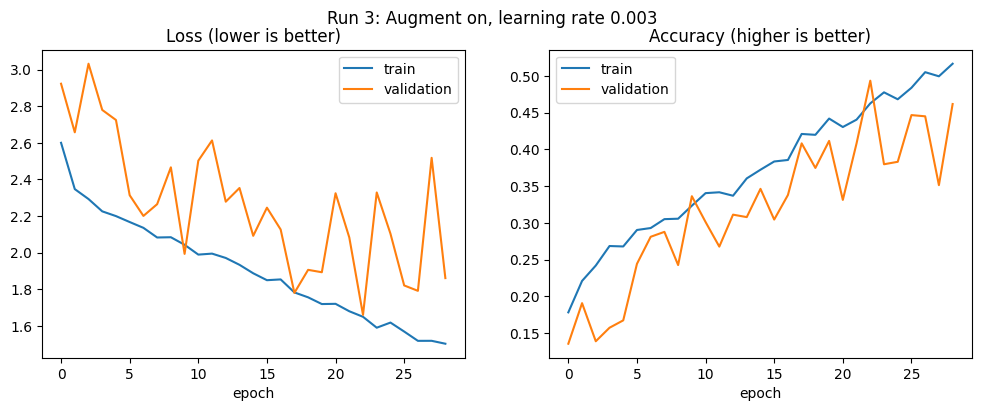

Run 3 | val_acc = 0.4933 | train_acc = 0.4624 | gap = -0.0309 | 0.6 min


In [8]:
# Experiment 3: build on whatever worked best so far
cfg = dict(baseline_cfg)
cfg["augment"] = True               # keep what helped
cfg["learning_rate"] = 0.003        # CHANGE: the new thing you are testing

model = run_experiment(cfg, notes="Augment on, learning rate 0.003")

Epoch 1/30
53/53 - 20s - 376ms/step - accuracy: 0.1870 - loss: 2.5721 - val_accuracy: 0.0619 - val_loss: 3.0121
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2687 - loss: 2.2431 - val_accuracy: 0.0569 - val_loss: 3.3605
Epoch 3/30
53/53 - 1s - 10ms/step - accuracy: 0.3200 - loss: 2.1167 - val_accuracy: 0.1204 - val_loss: 3.4566
Epoch 4/30
53/53 - 1s - 12ms/step - accuracy: 0.3459 - loss: 1.9985 - val_accuracy: 0.1187 - val_loss: 3.4079
Epoch 5/30
53/53 - 1s - 12ms/step - accuracy: 0.3742 - loss: 1.9237 - val_accuracy: 0.0970 - val_loss: 3.6807
Epoch 6/30
53/53 - 1s - 11ms/step - accuracy: 0.4070 - loss: 1.8115 - val_accuracy: 0.1472 - val_loss: 3.4364
Epoch 7/30
53/53 - 1s - 11ms/step - accuracy: 0.4379 - loss: 1.7344 - val_accuracy: 0.1656 - val_loss: 3.3393
Epoch 8/30
53/53 - 1s - 10ms/step - accuracy: 0.4550 - loss: 1.6572 - val_accuracy: 0.2191 - val_loss: 2.8711
Epoch 9/30
53/53 - 1s - 12ms/step - accuracy: 0.4763 - loss: 1.6118 - val_accuracy: 0.2759 - val_loss: 2.8712
Epoch 10

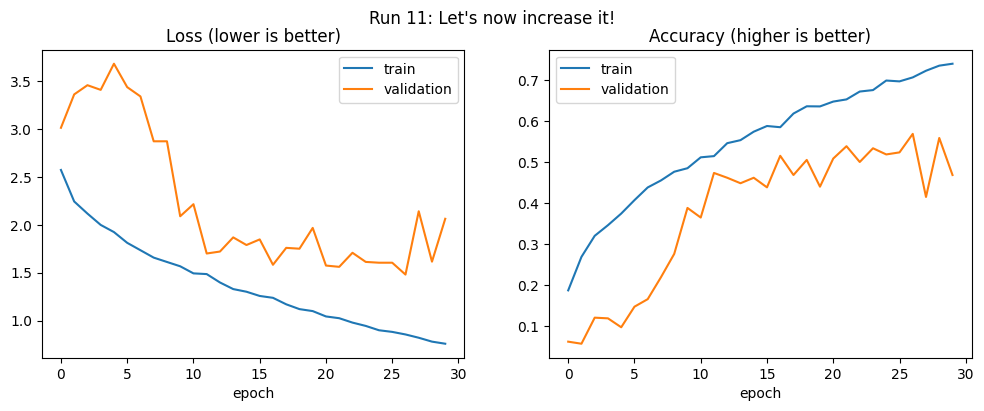

Run 11 | val_acc = 0.5686 | train_acc = 0.7063 | gap = 0.1377 | 0.6 min


In [20]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
#cfg["augment"] = True
cfg["learning_rate"] = 0.0009         # CHANGE

model = run_experiment(cfg, notes="So after about 10 trials, I find that 0.0009 is the optimal learning_rate")

Epoch 1/30
53/53 - 17s - 320ms/step - accuracy: 0.1398 - loss: 2.7712 - val_accuracy: 0.0686 - val_loss: 3.0199
Epoch 2/30
53/53 - 1s - 11ms/step - accuracy: 0.2017 - loss: 2.4600 - val_accuracy: 0.0602 - val_loss: 3.5082
Epoch 3/30
53/53 - 1s - 13ms/step - accuracy: 0.2256 - loss: 2.3707 - val_accuracy: 0.0769 - val_loss: 3.5343
Epoch 4/30
53/53 - 1s - 20ms/step - accuracy: 0.2630 - loss: 2.2712 - val_accuracy: 0.0736 - val_loss: 3.5102
Epoch 5/30
53/53 - 1s - 10ms/step - accuracy: 0.2639 - loss: 2.2418 - val_accuracy: 0.1204 - val_loss: 3.3290
Epoch 6/30
53/53 - 1s - 10ms/step - accuracy: 0.2973 - loss: 2.1809 - val_accuracy: 0.1120 - val_loss: 3.3205
Epoch 7/30
53/53 - 1s - 10ms/step - accuracy: 0.3046 - loss: 2.1418 - val_accuracy: 0.1589 - val_loss: 3.1712
Epoch 8/30
53/53 - 0s - 9ms/step - accuracy: 0.3194 - loss: 2.0749 - val_accuracy: 0.1505 - val_loss: 3.0985
Epoch 9/30
53/53 - 1s - 10ms/step - accuracy: 0.3282 - loss: 2.0345 - val_accuracy: 0.1839 - val_loss: 2.9281
Epoch 10/

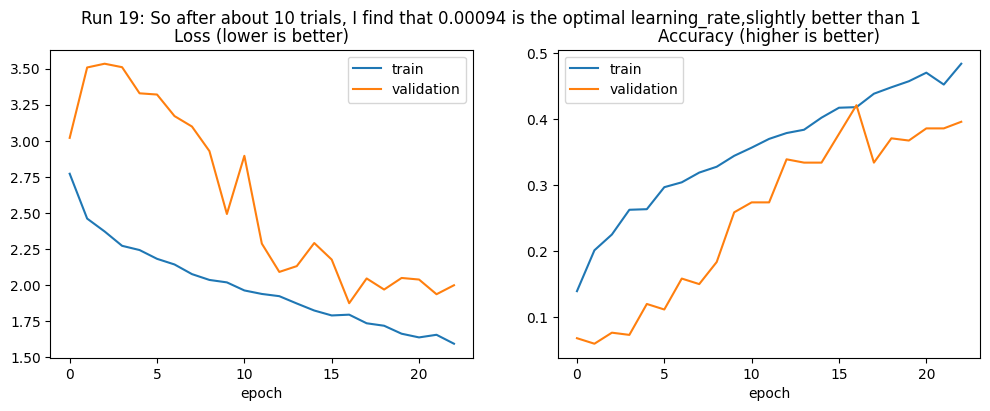

Run 19 | val_acc = 0.4214 | train_acc = 0.4185 | gap = -0.0029 | 0.5 min


In [28]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
#cfg["augment"] = True
cfg["learning_rate"] = 0.00094         # CHANGE
cfg["dropout"]=0.50;
model = run_experiment(cfg, notes="High dropout gives poor performance")

Epoch 1/30
53/53 - 10s - 186ms/step - accuracy: 0.1820 - loss: 2.6451 - val_accuracy: 0.0786 - val_loss: 3.1801
Epoch 2/30
53/53 - 2s - 42ms/step - accuracy: 0.2359 - loss: 2.3473 - val_accuracy: 0.0669 - val_loss: 3.3065
Epoch 3/30
53/53 - 2s - 41ms/step - accuracy: 0.2630 - loss: 2.2679 - val_accuracy: 0.0518 - val_loss: 3.6056
Epoch 4/30
53/53 - 2s - 41ms/step - accuracy: 0.2852 - loss: 2.1830 - val_accuracy: 0.0702 - val_loss: 3.6756
Epoch 5/30
53/53 - 2s - 41ms/step - accuracy: 0.3035 - loss: 2.1424 - val_accuracy: 0.1338 - val_loss: 3.1345
Epoch 6/30
53/53 - 2s - 42ms/step - accuracy: 0.3332 - loss: 2.0681 - val_accuracy: 0.1421 - val_loss: 3.3344
Epoch 7/30
53/53 - 2s - 43ms/step - accuracy: 0.3403 - loss: 2.0073 - val_accuracy: 0.1957 - val_loss: 2.9122
Epoch 8/30
53/53 - 2s - 42ms/step - accuracy: 0.3663 - loss: 1.9596 - val_accuracy: 0.2324 - val_loss: 2.7681
Epoch 9/30
53/53 - 2s - 43ms/step - accuracy: 0.3987 - loss: 1.8804 - val_accuracy: 0.2876 - val_loss: 2.2872
Epoch 10

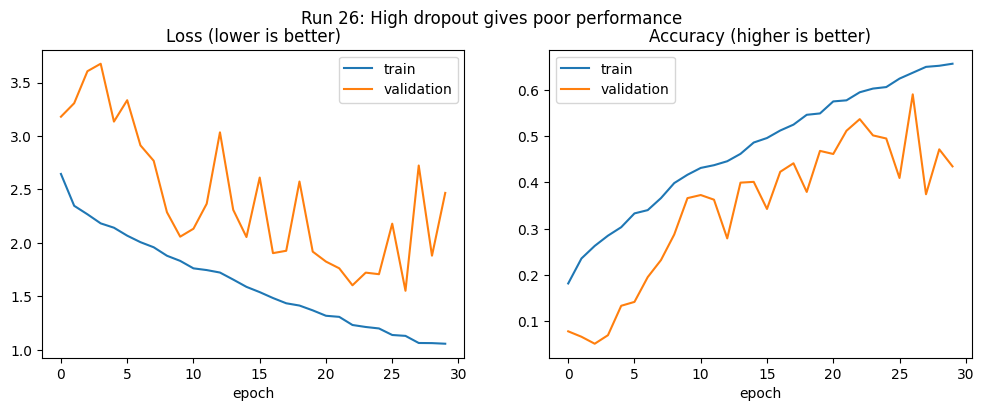

Run 26 | val_acc = 0.5903 | train_acc = 0.6370 | gap = 0.0467 | 1.2 min


In [35]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.00094         # CHANGE
cfg["dropout"]=0.24
cfg["base_filters"]=64
cfg["num_blocks"]=4
#cfg["use_lr_schedule"]=True
model = run_experiment(cfg, notes="Augmentation clearly bring validation acc closer to training acc and depth of the network increases both, Dynamic Duo!")

Epoch 1/50
53/53 - 9s - 160ms/step - accuracy: 0.1772 - loss: 2.6244 - val_accuracy: 0.0853 - val_loss: 3.2395
Epoch 2/50
53/53 - 2s - 32ms/step - accuracy: 0.2480 - loss: 2.3166 - val_accuracy: 0.0619 - val_loss: 3.5379
Epoch 3/50
53/53 - 2s - 33ms/step - accuracy: 0.2748 - loss: 2.2251 - val_accuracy: 0.1254 - val_loss: 3.2988
Epoch 4/50
53/53 - 2s - 33ms/step - accuracy: 0.3026 - loss: 2.1430 - val_accuracy: 0.1054 - val_loss: 3.6504
Epoch 5/50
53/53 - 2s - 33ms/step - accuracy: 0.3300 - loss: 2.0711 - val_accuracy: 0.1472 - val_loss: 3.5163
Epoch 6/50
53/53 - 2s - 33ms/step - accuracy: 0.3512 - loss: 2.0038 - val_accuracy: 0.1622 - val_loss: 3.4310
Epoch 7/50
53/53 - 2s - 33ms/step - accuracy: 0.3689 - loss: 1.9367 - val_accuracy: 0.1789 - val_loss: 2.8511
Epoch 8/50
53/53 - 2s - 33ms/step - accuracy: 0.4002 - loss: 1.8578 - val_accuracy: 0.2090 - val_loss: 2.9913
Epoch 9/50
53/53 - 2s - 33ms/step - accuracy: 0.4102 - loss: 1.8281 - val_accuracy: 0.3077 - val_loss: 2.4545
Epoch 10/

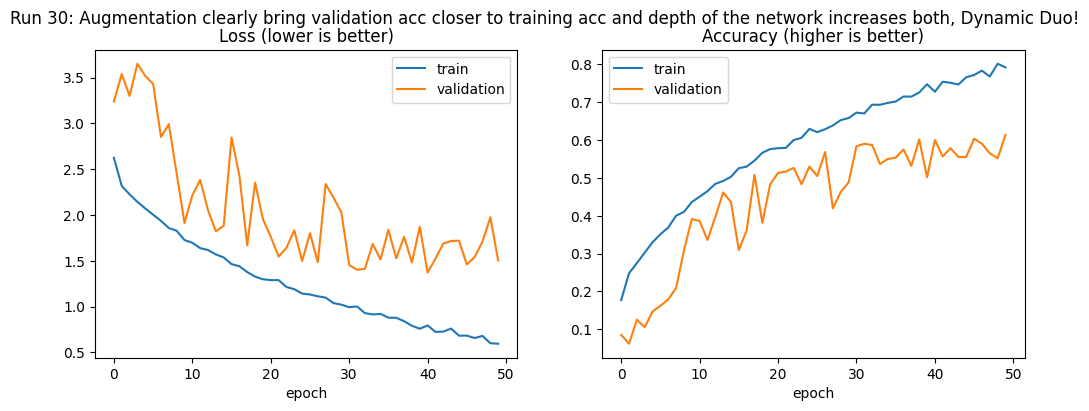

Run 30 | val_acc = 0.6137 | train_acc = 0.7921 | gap = 0.1784 | 1.5 min


In [40]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.00094         # CHANGE
cfg["dropout"]=0.25
cfg["base_filters"]=48
cfg["num_blocks"]=4
cfg["dense_units"]=768
cfg["epochs"]=50
cfg["patience"]=10
#cfg["use_lr_schedule"]=True
model = run_experiment(cfg, notes="Run more times and have more patience , drastic improvement!")

Epoch 1/100
53/53 - 20s - 376ms/step - accuracy: 0.1280 - loss: 3.1388 - val_accuracy: 0.0518 - val_loss: 5.3103
Epoch 2/100
53/53 - 7s - 123ms/step - accuracy: 0.1681 - loss: 2.5552 - val_accuracy: 0.0903 - val_loss: 3.8328
Epoch 3/100
53/53 - 6s - 116ms/step - accuracy: 0.1852 - loss: 2.4408 - val_accuracy: 0.0886 - val_loss: 3.4074
Epoch 4/100
53/53 - 6s - 108ms/step - accuracy: 0.2250 - loss: 2.3574 - val_accuracy: 0.0903 - val_loss: 3.5992
Epoch 5/100
53/53 - 6s - 107ms/step - accuracy: 0.2344 - loss: 2.3195 - val_accuracy: 0.1455 - val_loss: 3.1085
Epoch 6/100
53/53 - 6s - 106ms/step - accuracy: 0.2480 - loss: 2.2649 - val_accuracy: 0.1589 - val_loss: 3.1537
Epoch 7/100
53/53 - 5s - 102ms/step - accuracy: 0.2607 - loss: 2.2319 - val_accuracy: 0.1488 - val_loss: 3.0053
Epoch 8/100
53/53 - 5s - 101ms/step - accuracy: 0.2633 - loss: 2.1867 - val_accuracy: 0.1321 - val_loss: 3.0639
Epoch 9/100
53/53 - 5s - 103ms/step - accuracy: 0.2681 - loss: 2.1896 - val_accuracy: 0.2090 - val_loss

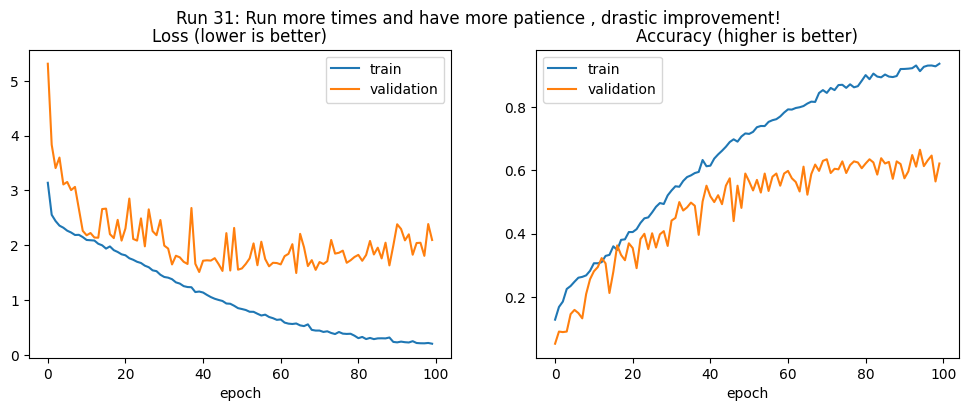

Run 31 | val_acc = 0.6656 | train_acc = 0.9142 | gap = 0.2486 | 9.6 min


In [41]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.00094         # CHANGE
cfg["dropout"]=0.25
cfg["base_filters"]=128
cfg["num_blocks"]=4
cfg["dense_units"]=1024
cfg["epochs"]=100
cfg["patience"]=20
#cfg["use_lr_schedule"]=True
model = run_experiment(cfg, notes="Two much of base_filters do not guarrenty better result")

Epoch 1/100
53/53 - 7s - 132ms/step - accuracy: 0.1572 - loss: 2.7374 - val_accuracy: 0.0769 - val_loss: 3.1728
Epoch 2/100
53/53 - 2s - 40ms/step - accuracy: 0.2185 - loss: 2.3745 - val_accuracy: 0.0686 - val_loss: 3.9031
Epoch 3/100
53/53 - 2s - 41ms/step - accuracy: 0.2554 - loss: 2.2988 - val_accuracy: 0.0836 - val_loss: 3.5725
Epoch 4/100
53/53 - 2s - 41ms/step - accuracy: 0.2654 - loss: 2.2114 - val_accuracy: 0.0853 - val_loss: 3.9260
Epoch 5/100
53/53 - 2s - 42ms/step - accuracy: 0.2825 - loss: 2.1537 - val_accuracy: 0.1087 - val_loss: 3.5160
Epoch 6/100
53/53 - 3s - 48ms/step - accuracy: 0.3150 - loss: 2.0903 - val_accuracy: 0.1622 - val_loss: 3.1759
Epoch 7/100
53/53 - 2s - 43ms/step - accuracy: 0.3403 - loss: 2.0075 - val_accuracy: 0.2475 - val_loss: 2.6423
Epoch 8/100
53/53 - 2s - 43ms/step - accuracy: 0.3615 - loss: 1.9334 - val_accuracy: 0.2609 - val_loss: 2.6189
Epoch 9/100
53/53 - 2s - 43ms/step - accuracy: 0.3760 - loss: 1.9119 - val_accuracy: 0.2692 - val_loss: 2.6870


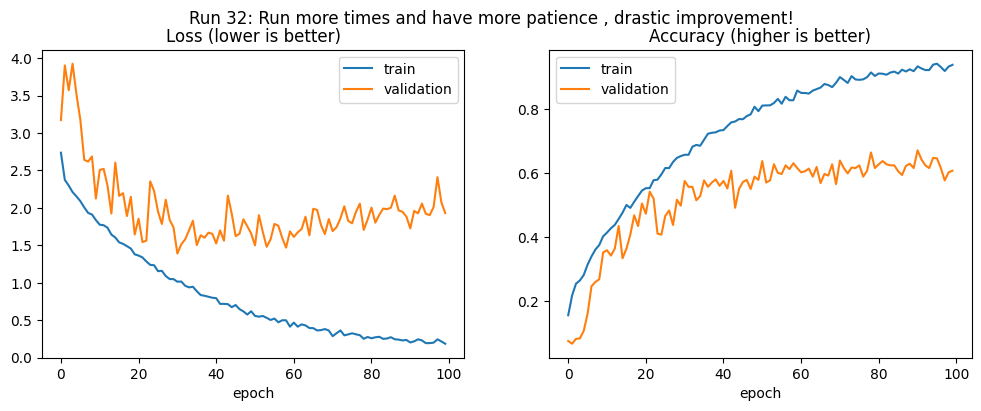

Run 32 | val_acc = 0.6706 | train_acc = 0.9319 | gap = 0.2613 | 3.8 min


In [42]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.00094         # CHANGE
cfg["dropout"]=0.25
cfg["base_filters"]=64
cfg["num_blocks"]=4
cfg["dense_units"]=1024
cfg["epochs"]=100
cfg["patience"]=20
#cfg["use_lr_schedule"]=True
model = run_experiment(cfg, notes="Best yet! Its about finding the sweet spot")

Epoch 1/100
27/27 - 7s - 268ms/step - accuracy: 0.1542 - loss: 5.0648 - val_accuracy: 0.0769 - val_loss: 5.2791
Epoch 2/100
27/27 - 2s - 66ms/step - accuracy: 0.2347 - loss: 4.4424 - val_accuracy: 0.0569 - val_loss: 5.5602
Epoch 3/100
27/27 - 2s - 67ms/step - accuracy: 0.2616 - loss: 4.1495 - val_accuracy: 0.0535 - val_loss: 5.3923
Epoch 4/100
27/27 - 2s - 68ms/step - accuracy: 0.2746 - loss: 3.8819 - val_accuracy: 0.0635 - val_loss: 5.2943
Epoch 5/100
27/27 - 2s - 68ms/step - accuracy: 0.2887 - loss: 3.6515 - val_accuracy: 0.0535 - val_loss: 4.8355
Epoch 6/100
27/27 - 2s - 68ms/step - accuracy: 0.3141 - loss: 3.4443 - val_accuracy: 0.0602 - val_loss: 5.6366
Epoch 7/100
27/27 - 2s - 68ms/step - accuracy: 0.3273 - loss: 3.2483 - val_accuracy: 0.0753 - val_loss: 4.7427
Epoch 8/100
27/27 - 2s - 68ms/step - accuracy: 0.3565 - loss: 3.0686 - val_accuracy: 0.0368 - val_loss: 4.9861
Epoch 9/100
27/27 - 2s - 70ms/step - accuracy: 0.3760 - loss: 2.9310 - val_accuracy: 0.1204 - val_loss: 5.0063


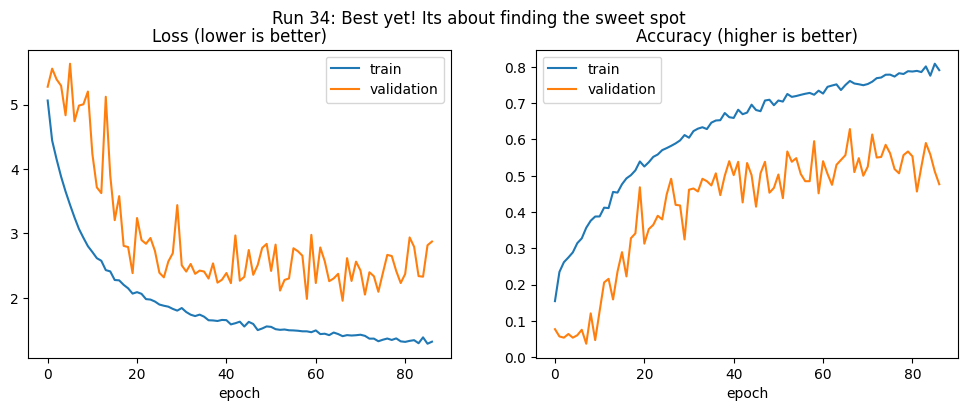

Run 34 | val_acc = 0.6288 | train_acc = 0.7614 | gap = 0.1327 | 2.8 min


In [45]:
# Experiment 4: copy this cell as many times as you need (use the + Code button)
cfg = dict(baseline_cfg)
cfg["augment"] = True
cfg["learning_rate"] = 0.00094         # CHANGE
cfg["dropout"]=0.25
cfg["base_filters"]=64
cfg["num_blocks"]=4
cfg["batch_size"]=128
cfg["dense_units"]=1024
cfg["epochs"]=100
cfg["l2"]=0.001
cfg["patience"]=20
#cfg["use_lr_schedule"]=True
model = run_experiment(cfg, notes="Best yet! Its about finding the sweet spot")

## Step 6: Your results table

This is your lab notebook. Look for patterns: which settings help, which hurt, which hardly matter. Copy the most interesting rows into the table in your README or report, and write one sentence about what you learned from each.

,run,notes,learning_rate,batch_size,optimizer,dropout,l2,base_filters,num_blocks,dense_units,augment,use_lr_schedule,train_acc,val_acc,gap,best_epoch,minutes
0,32,"Run more times and have more patience , drasti...",0.00094,64,adam,0.25,0.000,64,4,1024,True,False,0.9319,0.6706,0.2613,91,3.8
1,31,"Run more times and have more patience , drasti...",0.00094,64,adam,0.25,0.000,128,4,1024,True,False,0.9142,0.6656,0.2486,95,9.6
2,33,Best yet! Its about finding the sweet spot,0.00094,128,adam,0.25,0.000,64,4,1024,True,False,0.8876,0.6388,0.2488,69,2.9
3,34,Best yet! Its about finding the sweet spot,0.00094,128,adam,0.25,0.001,64,4,1024,True,False,0.7614,0.6288,0.1327,67,2.8
4,30,Augmentation clearly bring validation acc clos...,0.00094,64,adam,0.25,0.000,48,4,768,True,False,0.7921,0.6137,0.1784,50,1.5
5,9,Let's now increase it!,0.00090,64,adam,0.25,0.000,32,3,256,False,False,0.7322,0.5936,0.1386,27,0.5
6,26,High dropout gives poor performance,0.00094,64,adam,0.24,0.000,64,4,256,True,False,0.6370,0.5903,0.0467,27,1.2
7,1,"Baseline, nothing tuned",0.00100,64,adam,0.25,0.000,32,3,256,False,False,0.7160,0.5886,0.1274,25,0.8
8,15,"So after about 10 trials, I find that 0.00094 ...",0.00094,64,adam,0.20,0.000,32,3,256,False,False,0.6744,0.5769,0.0975,19,0.5
9,8,Let's now increase it!,0.00100,64,adam,0.25,0.000,32,3,256,False,False,0.6685,0.5719,0.0966,21,0.5


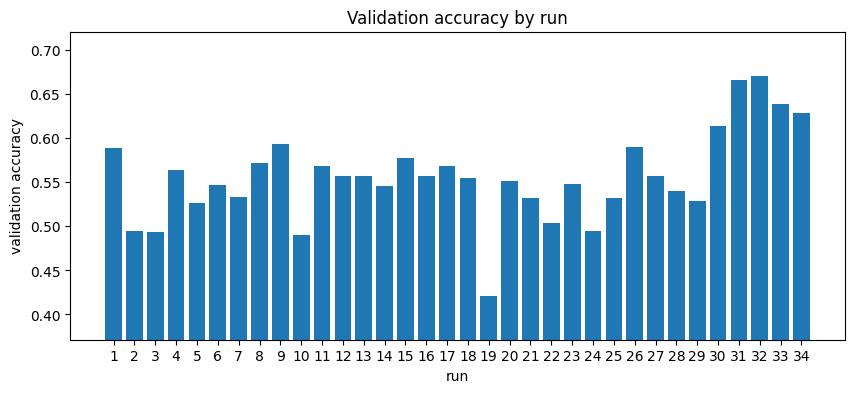

In [47]:
log_df = pd.DataFrame(experiment_log)
shown = [c for c in ["run", "notes", "learning_rate", "batch_size", "optimizer", "dropout", "l2",
                     "base_filters", "num_blocks", "dense_units", "augment", "use_lr_schedule",
                     "train_acc", "val_acc", "gap", "best_epoch", "minutes"] if c in log_df.columns]
display(log_df[shown].sort_values("val_acc", ascending=False).reset_index(drop=True))

plt.figure(figsize=(10, 4))
plt.bar(log_df["run"].astype(str), log_df["val_acc"])
plt.xlabel("run"); plt.ylabel("validation accuracy"); plt.title("Validation accuracy by run")
plt.ylim(max(0, log_df["val_acc"].min() - 0.05), min(1, log_df["val_acc"].max() + 0.05))
plt.show()

In [48]:
# Optional: download your log (and keep it safe, Colab deletes files when the session ends)
from google.colab import files
files.download("experiment_log.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 7: The final exam (run this ONCE)

When you are finished tuning, evaluate your best saved model on the test set. This tells you how well it will work on brand new images.

If you now go back and tune further because of this number, it stops being a fair test. So do this only when you are done.

In [46]:
best_model = keras.models.load_model(BEST_MODEL_FILE)
test_loss, test_acc = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Best validation accuracy during tuning: {best_val_so_far:.4f}")
print(f"FINAL TEST ACCURACY:                    {test_acc:.4f}")

# Which classes does the model handle best and worst?
preds = np.argmax(best_model.predict(x_test, verbose=0), axis=1)
per_class = pd.Series({CLASS_NAMES[c]: float(np.mean(preds[y_test == c] == c)) for c in range(NUM_CLASSES)}).sort_values()
print("\nHardest classes:\n", per_class.head(5).round(2).to_string())
print("\nEasiest classes:\n", per_class.tail(5).round(2).to_string())

Best validation accuracy during tuning: 0.6706
FINAL TEST ACCURACY:                    0.6478

Hardest classes:
 squirrel       0.44
bowl           0.46
caterpillar    0.49
clock          0.50
dolphin        0.52

Easiest classes:
 apple         0.79
beaver        0.80
keyboard      0.84
skyscraper    0.84
orange        0.85


## Reflection questions

Write short answers in a text cell or in your report:

1. Which single change gave the biggest improvement? Why do you think it helped?
2. Did any change make results worse? What does that teach you?
3. Look at the `gap` column. When was your model overfitting the most?
4. How different were your validation and test accuracy? What would a very large difference mean?
5. If you had two more hours, what would you try next?